In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import tensorflow as tf
from tensorflow import keras

In [2]:
data = pd.read_csv('D:\w اكسل\L 20\Airline_Delay_Cause.csv')
data.head()

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2022,5,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",136.0,7.0,5.95,0.00,...,0.0,1.00,0.0,0.0,255.0,222.0,0.0,4.0,0.0,29.0
1,2022,5,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",91.0,16.0,7.38,0.00,...,0.0,6.09,0.0,0.0,884.0,351.0,0.0,81.0,0.0,452.0
2,2022,5,9E,Endeavor Air Inc.,ACK,"Nantucket, MA: Nantucket Memorial",19.0,2.0,0.13,0.00,...,0.0,0.88,1.0,0.0,138.0,4.0,0.0,106.0,0.0,28.0
3,2022,5,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",88.0,14.0,7.26,0.76,...,0.0,1.64,0.0,0.0,947.0,585.0,35.0,125.0,0.0,202.0
4,2022,5,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",181.0,19.0,13.84,0.00,...,0.0,2.09,0.0,0.0,808.0,662.0,0.0,87.0,0.0,59.0


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318017 entries, 0 to 318016
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 318017 non-null  int64  
 1   month                318017 non-null  int64  
 2   carrier              318013 non-null  object 
 3   carrier_name         318013 non-null  object 
 4   airport              318014 non-null  object 
 5   airport_name         318017 non-null  object 
 6   arr_flights          317524 non-null  float64
 7   arr_del15            317285 non-null  float64
 8   carrier_ct           317525 non-null  float64
 9   weather_ct           317523 non-null  float64
 10  nas_ct               317529 non-null  float64
 11  security_ct          317529 non-null  float64
 12  late_aircraft_ct     317529 non-null  float64
 13  arr_cancelled        317529 non-null  float64
 14  arr_diverted         317527 non-null  float64
 15  arr_delay        

In [4]:

data.isna().sum()

year                     0
month                    0
carrier                  4
carrier_name             4
airport                  3
airport_name             0
arr_flights            493
arr_del15              732
carrier_ct             492
weather_ct             494
nas_ct                 488
security_ct            488
late_aircraft_ct       488
arr_cancelled          488
arr_diverted           490
arr_delay              494
carrier_delay          492
weather_delay          488
nas_delay              488
security_delay         490
late_aircraft_delay    488
dtype: int64

In [5]:
data.dropna(inplace=True)

In [6]:
data.isna().sum()

year                   0
month                  0
carrier                0
carrier_name           0
airport                0
airport_name           0
arr_flights            0
arr_del15              0
carrier_ct             0
weather_ct             0
nas_ct                 0
security_ct            0
late_aircraft_ct       0
arr_cancelled          0
arr_diverted           0
arr_delay              0
carrier_delay          0
weather_delay          0
nas_delay              0
security_delay         0
late_aircraft_delay    0
dtype: int64

In [7]:

categorical_cols = ['carrier', 'carrier_name', 'airport', 'airport_name']

for col in categorical_cols:
    # 1. تحويل نوع البيانات إلى فئوي (Category)
    data[col] = data[col].astype('category')
    
    # 2. استبدال القيم بالنصوص الرقمية المقابلة لها (Codes)
    data[col] = data[col].cat.codes

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 317261 entries, 0 to 318016
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 317261 non-null  int64  
 1   month                317261 non-null  int64  
 2   carrier              317261 non-null  int8   
 3   carrier_name         317261 non-null  int8   
 4   airport              317261 non-null  int16  
 5   airport_name         317261 non-null  int16  
 6   arr_flights          317261 non-null  float64
 7   arr_del15            317261 non-null  float64
 8   carrier_ct           317261 non-null  float64
 9   weather_ct           317261 non-null  float64
 10  nas_ct               317261 non-null  float64
 11  security_ct          317261 non-null  float64
 12  late_aircraft_ct     317261 non-null  float64
 13  arr_cancelled        317261 non-null  float64
 14  arr_diverted         317261 non-null  float64
 15  arr_delay            3

In [9]:
data['weather_delay'].min(),data['weather_delay'].max()

(0.0, 57707.0)

In [10]:
def value(x):
    if x <= 30:
        return 0
    elif x <=100:
        return 1
    elif x <=200:
        return 2
    else:
        return 3
data['WDcase']=data['weather_delay'].apply(lambda x: value(x))
data['WDcase'].value_counts()

WDcase
0    164984
3     68251
1     50127
2     33899
Name: count, dtype: int64

In [11]:
data.shape

(317261, 22)

In [12]:
x=data.drop(['WDcase','weather_delay'],axis=1)
y=data['WDcase']

In [13]:
x

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,nas_delay,security_delay,late_aircraft_delay
0,2022,5,0,13,0,10,136.0,7.0,5.95,0.00,0.05,0.0,1.00,0.0,0.0,255.0,222.0,4.0,0.0,29.0
1,2022,5,0,13,4,6,91.0,16.0,7.38,0.00,2.54,0.0,6.09,0.0,0.0,884.0,351.0,81.0,0.0,452.0
2,2022,5,0,13,5,259,19.0,2.0,0.13,0.00,1.00,0.0,0.88,1.0,0.0,138.0,4.0,106.0,0.0,28.0
3,2022,5,0,13,11,9,88.0,14.0,7.26,0.76,4.35,0.0,1.64,0.0,0.0,947.0,585.0,125.0,0.0,202.0
4,2022,5,0,13,12,21,181.0,19.0,13.84,0.00,3.07,0.0,2.09,0.0,0.0,808.0,662.0,87.0,0.0,59.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318012,2003,6,7,12,352,352,480.0,84.0,25.69,3.09,33.96,0.0,21.26,0.0,0.0,3744.0,978.0,1023.0,0.0,1579.0
318013,2003,6,7,12,354,337,505.0,111.0,21.78,2.24,73.81,0.0,13.17,3.0,0.0,4284.0,1376.0,2132.0,0.0,638.0
318014,2003,6,7,12,361,338,146.0,36.0,6.99,0.00,26.85,0.0,2.15,0.0,0.0,896.0,205.0,607.0,0.0,84.0
318015,2003,6,7,12,363,339,95.0,13.0,3.66,0.00,7.92,0.0,1.42,0.0,0.0,367.0,120.0,210.0,0.0,37.0


In [14]:
y

0         0
1         0
2         0
3         1
4         0
         ..
318012    2
318013    2
318014    0
318015    0
318016    3
Name: WDcase, Length: 317261, dtype: int64

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=.25,random_state=42,shuffle=True)

In [17]:
print("x_train:",x_train.shape)
print("y_train:",y_train.shape)
print("x_test:",x_test.shape)
print("y_test:",y_test.shape)

x_train: (237945, 20)
y_train: (237945,)
x_test: (79316, 20)
y_test: (79316,)


In [18]:
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)

x_train shape: (237945, 20)
y_train shape: (237945,)


In [19]:
y_cat=tf.keras.utils.to_categorical(y)
y[:20]

0     0
1     0
2     0
3     1
4     0
5     1
6     3
7     0
8     0
9     0
10    1
11    0
12    0
13    0
14    0
15    0
18    0
19    1
20    0
21    0
Name: WDcase, dtype: int64

In [20]:
y_cat[:20]

array([[1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 0., 1.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.]])

In [21]:
x_train,x_test,y_train,y_test= train_test_split(x,y_cat,test_size=.25,random_state=42)

In [22]:
y_train

array([[0., 0., 0., 1.],
       [0., 0., 0., 1.],
       [0., 0., 0., 1.],
       ...,
       [1., 0., 0., 0.],
       [0., 0., 1., 0.],
       [1., 0., 0., 0.]], shape=(237945, 4))

In [23]:
print("x_train:",x_train.shape)
print("y_train:",y_train.shape)
print("x_test:",x_test.shape)
print("y_test:",y_test.shape)

x_train: (237945, 20)
y_train: (237945, 4)
x_test: (79316, 20)
y_test: (79316, 4)


In [24]:
kerasmodel=keras.models.Sequential([
    keras.Input(shape=(20,)),
    keras.layers.Dense(8,activation='tanh'),
    # keras.layers.Dropout(0.1),
    keras.layers.Dense(128,activation='tanh'),
     # keras.layers.Dropout(0.3),
    keras.layers.Dense(64,activation='tanh'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(4,activation='softmax')])#عشان هنا بأعمل ملتي كلاسفيكيشن softmax

In [25]:
my_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001,
    weight_decay=0.004,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-07
)

In [26]:
kerasmodel.compile(optimizer=my_optimizer,loss ='categorical_crossentropy',metrics=['accuracy'])

In [27]:
history = kerasmodel.fit(
    x_train,               
    y_train, 
    validation_data=(x_test, y_test),  # يجب تمرير بيانات التحقق داخل قوسين (Tuple)
    epochs=100,            # يتم تمرير المعاملات داخل دالة fit وليس بنقاط خارجية
    batch_size=1000, 
    verbose=1, 
    callbacks=[ tf.keras.callbacks.EarlyStopping(patience=10, monitor='val_accuracy') ])

Epoch 1/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5583 - loss: 1.0502 - val_accuracy: 0.6017 - val_loss: 1.0065
Epoch 2/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6195 - loss: 0.9903 - val_accuracy: 0.6314 - val_loss: 0.9745
Epoch 3/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6290 - loss: 0.9642 - val_accuracy: 0.6131 - val_loss: 0.9562
Epoch 4/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6491 - loss: 0.9110 - val_accuracy: 0.6845 - val_loss: 0.8266
Epoch 5/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7103 - loss: 0.7182 - val_accuracy: 0.7253 - val_loss: 0.6224
Epoch 6/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7565 - loss: 0.5596 - val_accuracy: 0.7773 - val_loss: 0.5120
Epoch 7/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7788 - loss: 0.5121 - val_accuracy: 0.7840 - val_loss: 0.5188
Epoch 8/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7803 - loss: 0.5003 - val_accu

In [28]:
print(kerasmodel.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 8)                   │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 4)                   │             260 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,510 (115.28 KB)

 Trainable params: 9,836 (38.42 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 19,674 (76.86 KB)

None


In [29]:
y_predict=kerasmodel.predict(x_test)

2479/2479 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


In [30]:
print(y_predict.shape)

(79316, 4)


In [31]:
print(format(y_predict[:5]))

[[2.3987354e-08 1.6637383e-05 4.7829235e-03 9.9520040e-01]
 [2.7247402e-04 4.6404421e-01 5.3229314e-01 3.3901674e-03]
 [3.8625655e-04 6.1028349e-01 3.8790122e-01 1.4289536e-03]
 [9.9592376e-01 4.0666014e-03 9.5715359e-06 1.6428773e-08]
 [3.8625655e-04 6.1028349e-01 3.8790122e-01 1.4289536e-03]]


In [32]:
# 2. تحويلها إلى 0 أو 1 بناءً على عتبة 0.5
y_predict_classes = np.argmax(y_predict, axis=1)
y_test_classes=np.argmax(y_test,axis=1)

In [33]:
print(format(y_predict_classes[:10]))

[3 2 1 0 1 1 3 3 1 1]


In [34]:
y_test_classes[:10]

array([3, 1, 1, 0, 2, 2, 3, 3, 1, 1])

In [35]:
modelloss,modelAccurcy=kerasmodel.evaluate(x_test,y_test)
print("Moel loss is {}".format(modelloss))
print("Moel Accurcy is {}".format(modelAccurcy))

2479/2479 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8883 - loss: 0.2011
Moel loss is 0.2011178731918335
Moel Accurcy is 0.888332724571228


In [36]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


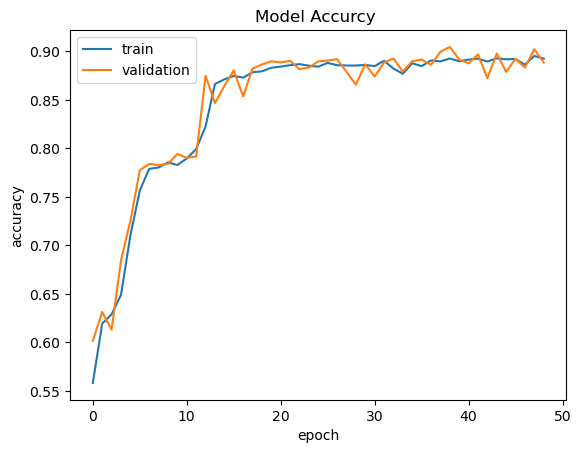

In [37]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accurcy ')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','validation'],loc='upper left')
plt.show()

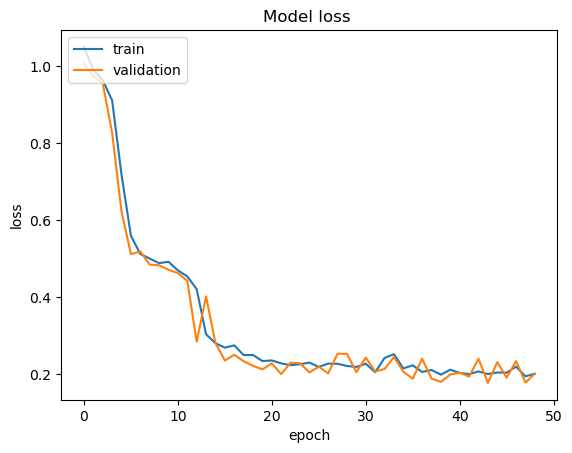

In [38]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss ')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','validation'],loc='upper left')
plt.show()

In [39]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


In [40]:
model_confusion_matrix=confusion_matrix(y_test_classes,y_predict_classes)
print("Confusion_matrix is \n ",model_confusion_matrix)#القيم المتوقعة والقيم الخطأفي توقعها بالنسبة للواحد والزيرو

Confusion_matrix is 
  [[40144  1017    10     0]
 [    0 10446  2049     0]
 [    0  5524  3003    45]
 [    0     2   210 16866]]


In [41]:
from sklearn.metrics import classification_report

# طباعة تقرير الدقة المفصل للفئات الأربعة
print("Classification Report:\n")
print(classification_report(y_test_classes, y_predict_classes))


Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     41171
           1       0.61      0.84      0.71     12495
           2       0.57      0.35      0.43      8572
           3       1.00      0.99      0.99     17078

    accuracy                           0.89     79316
   macro avg       0.80      0.79      0.78     79316
weighted avg       0.89      0.89      0.88     79316



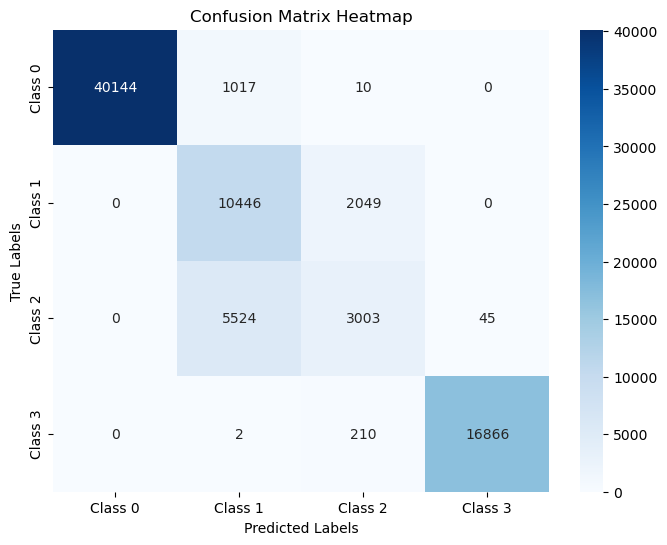

In [42]:
import seaborn as sns

plt.figure(figsize=(8, 6))
# رسم المصفوفة كخريطة حرارية ملونة
sns.heatmap(model_confusion_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Class 0', 'Class 1', 'Class 2', 'Class 3'],
            yticklabels=['Class 0', 'Class 1', 'Class 2', 'Class 3'])

plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix Heatmap')
plt.show()

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [45]:
# قراءة البيانات
data = pd.read_csv(r'D:\w اكسل\L 20\Airline_Delay_Cause.csv')
data.dropna(inplace=True)

In [46]:
# ترميز الفئات
categorical_cols = ['carrier', 'carrier_name', 'airport', 'airport_name']
for col in categorical_cols:
    data[col] = data[col].astype('category').cat.codes
# إنشاء المتغير الهدف (4 فئات)
def get_wd_case(x):
    if x <= 30: return 0
    elif x <= 100: return 1
    elif x <= 200: return 2
    else: return 3

In [47]:
data['WDcase'] = data['weather_delay'].apply(get_wd_case)

In [48]:
# فصل المدخلات والهدف (مع تجنب تسريب البيانات)
x = data.drop(['WDcase', 'weather_delay'], axis=1)
y = data['WDcase']

In [49]:
# تحويل Target إلى One-Hot Encoding
y_cat = tf.keras.utils.to_categorical(y, num_classes=4)

In [50]:
# تقسيم البيانات
x_train, x_test, y_train, y_test = train_test_split(x, y_cat, test_size=0.25, random_state=42, shuffle=True)
# تقييس البيانات (Feature Scaling)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [51]:
model = keras.models.Sequential([
    keras.Input(shape=(x_train_scaled.shape[1],)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(4, activation='softmax') # تصنيف متعدد الفئات (Multi-class)
])

In [52]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

In [53]:
history = model.fit(
    x_train_scaled,               
    y_train, 
    validation_data=(x_test_scaled, y_test),
    epochs=100,            
    batch_size=1000, 
    verbose=1, 
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=10, monitor='val_accuracy', restore_best_weights=True)]
)

Epoch 1/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7195 - loss: 0.6965 - val_accuracy: 0.7929 - val_loss: 0.4695
Epoch 2/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7963 - loss: 0.4633 - val_accuracy: 0.7997 - val_loss: 0.4457
Epoch 3/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8022 - loss: 0.4439 - val_accuracy: 0.8037 - val_loss: 0.4348
Epoch 4/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8059 - loss: 0.4335 - val_accuracy: 0.8063 - val_loss: 0.4292
Epoch 5/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8078 - loss: 0.4271 - val_accuracy: 0.8079 - val_loss: 0.4232
Epoch 6/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8094 - loss: 0.4217 - val_accuracy: 0.8089 - val_loss: 0.4198
Epoch 7/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8108 - loss: 0.4181 - val_accuracy: 0.8107 - val_loss: 0.4143
Epoch 8/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8127 - loss: 0.4132 - val_accu

In [55]:
y_predict = model.predict(x_test_scaled)
# استخراج الفئة المتوقعة ذات الاحتمال الأعلى لكل عينة
y_pred_classes = np.argmax(y_predict, axis=1)
y_true_classes = np.argmax(y_test, axis=1)
print("أول 10 توقعات (أرقام الفئات):", y_pred_classes[:10])
print(" أول 10 قيم حقيقية (أرقام الفئات)):", y_true_classes[:10])

2479/2479 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
أول 10 توقعات (أرقام الفئات): [3 1 1 0 2 2 3 3 2 1]
 أول 10 قيم حقيقية (أرقام الفئات)): [3 1 1 0 2 2 3 3 1 1]


In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
# 1. قراءة البيانات وتنظيف القيم المفقودة
data = pd.read_csv(r'D:\w اكسل\L 20\Airline_Delay_Cause.csv')
data.dropna(inplace=True)
# 2. إنشاء المتغير الهدف (WDcase - 4 فئات)
def get_wd_case(x):
    if x <= 30: return 0
    elif x <= 100: return 1
    elif x <= 200: return 2
    else: return 3
data['WDcase'] = data['weather_delay'].apply(get_wd_case)
# 3. إزالة جميع الأعمدة المرتبطة بالتأخير وعداداته كلياً لمنع تسريب البيانات (Data Leakage)
leakage_cols = [
    'weather_delay', 'WDcase', 
    'arr_del15', 'carrier_ct', 'weather_ct', 'nas_ct', 'security_ct', 'late_aircraft_ct',
    'arr_delay', 'carrier_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay'
]
# مصفوفة المدخلات X الحقيقية الخالية تماماً من التسريب
X = data.drop(columns=leakage_cols)
y = data['WDcase']
# 4. معالجة المتغيرات الفئوية (Categorical Features)
# استخدام One-Hot Encoding للمتغيرات ذات القيم القليلة مثل الشهر وشركة الطيران
X = pd.get_dummies(X, columns=['carrier', 'month'], drop_first=True)
# ترميز المطارات وأسماء الشركات كرموز فئوية
for col in ['carrier_name', 'airport', 'airport_name']:
    X[col] = X[col].astype('category').cat.codes
# 5. تحويل الهدف إلى One-Hot Encoding للتصنيف المتعدد
y_cat = tf.keras.utils.to_categorical(y, num_classes=4)
# 6. تقسيم البيانات إلى تدريب واختبار مع الحفاظ على نسبة التوزيع (Stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_cat, test_size=0.25, random_state=42,stratify=y
)
# 7. تقييس البيانات (Feature Scaling) - الحساب على بيانات التدريب فقط لمنع التسريب
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# 8. بناء بنية النموذج المحسّنة (مع إضافة BatchNormalization و Dropout لمنع Overfitting)
model = keras.models.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(4, activation='softmax') # تصنيف متعدد الفئات
])
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
# 9. التوقف المبكر مع استعادة أفضل الأوزان (restore_best_weights=True)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)
# 10. تدريب النموذج
history = model.fit(
    X_train_scaled,               
    y_train, 
    validation_data=(X_test_scaled, y_test),
    epochs=100,            
    batch_size=1000, 
    verbose=1, 
    callbacks=[early_stopping]
)
# 11. التنبؤ والتقييم الدقيق
y_pred_probs = model.predict(X_test_scaled)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test, axis=1)
# طباعة التقرير الشامل
print("\n--- تقرير التقييم الدقيق (Classification Report) ---")
print(classification_report(y_true_classes, y_pred_classes))

Epoch 1/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.5824 - loss: 1.0918 - val_accuracy: 0.6198 - val_loss: 0.9992
Epoch 2/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6216 - loss: 0.9973 - val_accuracy: 0.6339 - val_loss: 0.9550
Epoch 3/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6332 - loss: 0.9637 - val_accuracy: 0.6415 - val_loss: 0.9370
Epoch 4/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6396 - loss: 0.9420 - val_accuracy: 0.6414 - val_loss: 0.9372
Epoch 5/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6438 - loss: 0.9271 - val_accuracy: 0.6476 - val_loss: 0.9105
Epoch 6/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6464 - loss: 0.9184 - val_accuracy: 0.6493 - val_loss: 0.9057
Epoch 7/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6477 - loss: 0.9136 - val_accuracy: 0.6506 - val_loss: 0.9011
Epoch 8/100
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6486 - loss: 0.9093 - 